# SpamJam: modelling

SpamJam flags spam (`is_spam` = 1) for GrandPied's IT team. The problem is described in the README, and the data is explored and split in `data_exploration.ipynb`. Here we build and compare models on the training set, then evaluate the final model once on the test set.

**What guides our choices.** For GrandPied, a false positive (a client email flagged as spam) costs more than a false negative (spam that gets through). So:
- **Metric:** we compare models with average precision, then pick a decision threshold on out-of-fold predictions that keeps precision on spam high.
- **Protocol:** every choice is made on the training set with cross-validation; the test set is used once, at the end.

**Scope.** This is a proof of concept on Spambase, whose legitimate emails all come from one person. GrandPied would retrain the model on its own emails before real use.

## Setup

**Preprocessing pipeline.** All steps run inside a scikit-learn `Pipeline`, so each CV fold learns them from its training part only.

- **Capital-letter counts:** log, then `StandardScaler`. They are very skewed (see `data_exploration.ipynb`).
- **Other features:** `StandardScaler` only.
- **No imputation** (no missing values) and **no encoding** (all features are numeric).

We scale because k-NN, the linear SVM and regularised logistic regression are sensitive to feature size.

**Decision rule:** an option wins only if its CV average precision beats the other by more than one standard error; otherwise we keep the simpler one.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    f1_score,
    make_scorer,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate
from sklearn.preprocessing import FunctionTransformer

from spamjam.config import load_config
from spamjam.constants import SPAM, TARGET_COL
from spamjam.data import DatasetLoader
from spamjam.evaluate import CONFUSION_MATRIX
from spamjam.models import Trainer

config = load_config()
donor = config["features"]["donor_columns"]

loader = DatasetLoader.from_config()
train_df, _ = loader.load_or_create_split()   # test set not used until the end
X_train = train_df.drop(columns=TARGET_COL)
y_train = train_df[TARGET_COL]

# The same CV as the Trainer, for the few steps that don't go through it.
cv = StratifiedKFold(
    n_splits=config["cv"]["n_splits"], shuffle=True, random_state=config["random_state"]
)


def make_trainer(name: str, grid: dict) -> Trainer:
    """A Trainer with the CV settings from config.yaml, for the given grid."""
    return Trainer(
        name,
        param_grid=grid,
        n_splits=config["cv"]["n_splits"],
        scoring=config["cv"]["scoring"],
        random_state=config["random_state"],
    )

## Baseline: dummy classifier

A `DummyClassifier` always predicts the most frequent class (ham), without looking at the emails. Any real model must clearly beat it, otherwise the features are useless. We score it with the same CV as the other models.

`zero_division=0`: the dummy never predicts spam, so precision would divide by zero; we count it as 0 instead of raising a warning.

In [2]:
dummy_model = DummyClassifier(strategy="most_frequent")
scoring = {
    "average_precision": "average_precision",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc",
}
dummy_scores = cross_validate(dummy_model, X_train, y_train, cv=cv, scoring=scoring)

pd.Series(
    {name: dummy_scores[f"test_{name}"].mean() for name in scoring},
    name="Dummy baseline",
).round(4)

average_precision    0.3988
precision            0.0000
recall               0.0000
f1                   0.0000
roc_auc              0.5000
Name: Dummy baseline, dtype: float64

**Result.** The dummy never predicts spam, so its precision, recall and F1 are 0, and its ROC-AUC is 0.5 (no better than chance). Its **average precision equals the share of spam in the training set (about 0.40)**: that is the floor for our main metric. Every model below must score well above it.

## Model selection

We first use logistic regression to settle the preprocessing (log transform or not) and the regularisation (L1 or L2). Then we compare it with k-NN and a linear SVM, tune all three, and choose the final model.

### Logistic regression: log transform and L1 vs L2

In [3]:
grid = {
    "preprocess__capital__log": [
        FunctionTransformer(np.log1p, feature_names_out="one-to-one"),
        "passthrough",                      # = no log transform
    ],
    **config["grids"]["logistic_regression"],   # C and penalty values
}
trainer = make_trainer("logistic_regression", grid)
trainer.train(X_train, y_train)
search = trainer.search

In [4]:
results = pd.DataFrame(search.cv_results_)

results["log"] = results["param_preprocess__capital__log"].map(
    lambda v: "no" if isinstance(v, str) else "yes")
cols = ["log", "param_model__penalty", "param_model__C",
        "mean_test_score", "std_test_score"]
best = results.loc[results.groupby(["log", "param_model__penalty"])
                   ["mean_test_score"].idxmax(), cols]
best.sort_values("mean_test_score", ascending=False).round(4)

,log,param_model__penalty,param_model__C,mean_test_score,std_test_score
8,yes,l1,1.0,0.9542,0.0111
14,yes,l2,10.0,0.9530,0.0091
9,no,l1,1.0,0.9434,0.0112
19,no,l2,100.0,0.9432,0.0114


**Decisions.**
- **Log transform: keep it.** With the log, the best CV average precision is about 0.954; without it, about 0.943. The gain (~0.011) is about two standard errors, so it is a real improvement.
- **L1 vs L2: L1.** The best L1 (C=1) and L2 (C=10) scores differ by about 0.001, well within one standard error. With equal scores, we keep L1: it also removes the two redundant features (`857` and `415`, see below), so the model uses fewer features.

### Is the grid wide enough?

If the best `C` were at the edge of the grid (0.01 or 100), a value outside it might be better. The table shows the CV score for every `C`.

In [5]:
results.pivot_table(
    index="param_model__C",
    columns=["log", "param_model__penalty"],
    values="mean_test_score",
).round(4)

log                       no             yes        
param_model__penalty      l1      l2      l1      l2
param_model__C                                      
0.01                  0.9150  0.9335  0.9204  0.9428
0.10                  0.9426  0.9417  0.9507  0.9506
1.00                  0.9434  0.9406  0.9542  0.9512
10.00                 0.9433  0.9425  0.9526  0.9530
100.00                0.9433  0.9432  0.9519  0.9522

With the log transform (the version we keep), L1's best `C` (1) scores higher than both its neighbours (0.1 and 10), and L2's best `C` (10) scores higher than `C`=100, so both are inside the grid. Without the log transform, L2 is still improving slightly at the edge (0.9432 at `C`=100), but that version is about 0.01 below the log version, so a wider grid would not change our choice.

### Coefficients: L1 vs L2

We refit the best L1 and best L2 pipelines on the training set and compare their 20 largest weights. A positive weight pushes an email towards spam, a negative one towards ham. Features are scaled, so sizes can be compared.

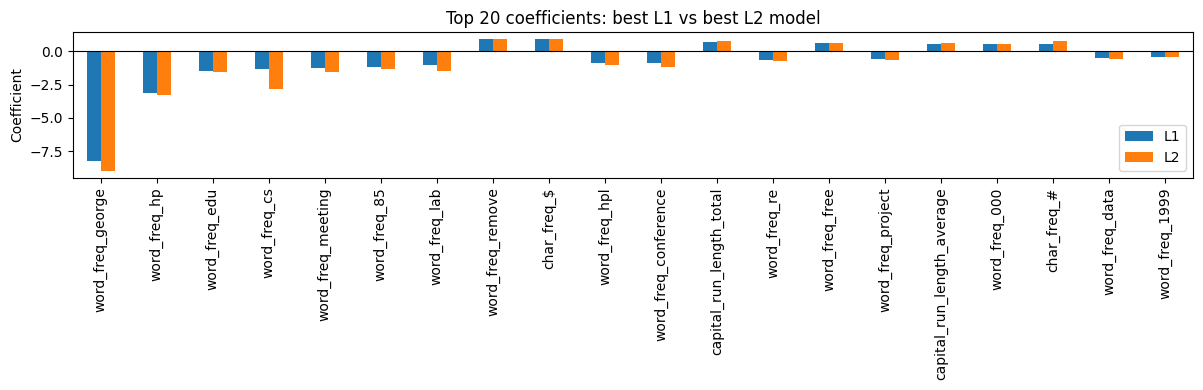

L1 sets 2 of 57 coefficients to zero.


In [6]:
from sklearn.base import clone


def refit_best(penalty: str):
    """Refit the best pipeline for one penalty (with the log transform)."""
    rows = results[
        (results["log"] == "yes") & (results["param_model__penalty"] == penalty)
    ]
    params = rows.loc[rows["mean_test_score"].idxmax(), "params"]
    return clone(search.estimator).set_params(**params).fit(X_train, y_train)


models = {"L1": refit_best("l1"), "L2": refit_best("l2")}
names = models["L1"]["preprocess"].get_feature_names_out()
coefs = pd.DataFrame(
    {label: m["model"].coef_[0] for label, m in models.items()},
    index=[n.split("__", 1)[1] for n in names],
)

top = coefs.loc[coefs["L1"].abs().sort_values(ascending=False).index[:20]]
top.plot.bar(figsize=(12, 4), title="Top 20 coefficients: best L1 vs best L2 model")
plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("Coefficient")
plt.tight_layout()
plt.show()

print(f"L1 sets {(coefs['L1'] == 0).sum()} of {len(coefs)} coefficients to zero.")

Both models agree on the main signals. The largest weight by far is `word_freq_george` (strongly towards ham), followed by other donor-related words (`hp`, `edu`, `cs`, `meeting`, `lab`), while `remove`, `$` and capital letters push towards spam. L1 sets only `857` and `415` to zero, the two near-duplicate features (correlation 0.994). This dependence on the donor's words is what we test next.

### Donor-specific words

Some words describe the dataset's donor (George, at HP Labs) rather than spam: `george`, `hp`, `hpl`, `650`, `857`, `415`, `labs`, `telnet`, `technology` (see `data_exploration.ipynb`). We rerun the search without them.

CV can only partly judge this: its folds come from the same donor, so these words look useful here even though they wouldn't help on GrandPied's emails.

In [7]:
trainer_dropped = make_trainer("logistic_regression", grid)
trainer_dropped.train(X_train.drop(columns=donor), y_train)
search_dropped = trainer_dropped.search

std_best = search.cv_results_["std_test_score"][search.best_index_]
one_se = std_best / np.sqrt(cv.get_n_splits())

print(f"All features:        {search.best_score_:.4f}")
print(f"Without donor words: {search_dropped.best_score_:.4f}")
print(f"Difference:          {search.best_score_ - search_dropped.best_score_:.4f}")
print(f"One standard error:  {one_se:.4f}")

All features:        0.9542
Without donor words: 0.9382
Difference:          0.0160
One standard error:  0.0050


**Decision: keep them.** Dropping them lowers CV average precision from about 0.954 to 0.938 (about three standard errors). That gain comes from the donor's own emails and wouldn't carry over to GrandPied. Since this is a proof of concept on Spambase, we keep them and report the limitation: our scores are likely optimistic for GrandPied, and the model must be retrained on GrandPied's own emails before real use.

### Other models with default settings

Before tuning, we run each model with scikit-learn's default settings through the same `Trainer`: the same pipeline (log on capital counts, then scaling), the same stratified 5-fold CV and the same score (average precision). This checks that every model trains, and gives a first idea of how they compare.

- **Logistic regression**: a linear model, with probabilities built in.
- **k-NN**: labels an email like its 5 closest training emails. It relies on distances, which is why we scale the features.
- **Linear SVM**: a linear model that maximises the margin between spam and ham. We use `SVC(kernel="linear", probability=True)` because `LinearSVC` cannot give probabilities, and our metrics need them.

In [8]:
rows = []
for name in config["grids"]:
    default_trainer = make_trainer(name, {})  # empty grid: default settings only
    default_trainer.train(X_train, y_train)
    cv_results = default_trainer.search.cv_results_
    rows.append({
        "model": name,
        "mean AP": cv_results["mean_test_score"][0],
        "std AP": cv_results["std_test_score"][0],
        "fit time (s)": cv_results["mean_fit_time"][0],
    })

initial = pd.DataFrame(rows).sort_values("mean AP", ascending=False)
initial.round(4)

,model,mean AP,std AP,fit time (s)
0,logistic_regression,0.9512,0.0098,0.0238
2,linear_svm,0.9498,0.0115,0.5217
1,knn,0.9209,0.0107,0.0043


**First results** (CV average precision, default settings):

- **Logistic regression (0.951) and linear SVM (0.950) are tied**: the gap (0.001) is well below one standard error (about 0.004). Both are linear models, so they find similar boundaries. The SVM is the slowest to train, because `probability=True` adds an extra internal cross-validation.
- **k-NN is clearly behind (0.921)**, about seven standard errors below. With 57 features, mostly zeros, distances between emails are less informative. Tuning the number of neighbours may help.
- All three are far above the dummy baseline, whose average precision is the spam rate (about 0.40).

These are untuned scores. The tuned comparison and the choice of the final model are done later on.

### Tuning all models

We now tune every model with its grid from `config.yaml`, through the same `Trainer`: same pipeline, same stratified 5-fold CV, same metric (average precision). As for `C` above, the best value of each hyperparameter should be inside its grid, not at the edge; otherwise a value outside the grid might be better.

**Note:** the next cell takes a few minutes (about 3), mostly for the linear SVM at large `C`. It prints its progress while it runs.

In [9]:
rows = []
trainers = {}
print("Tuning in progress (about 3 minutes, good models take time)...")
for name, model_grid in config["grids"].items():
    print(f"  {name}...", end=" ", flush=True)
    start = time.time()
    trainers[name] = make_trainer(name, model_grid)
    trainers[name].train(X_train, y_train)
    print(f"done in {time.time() - start:.0f} s")
    tuned_search = trainers[name].search
    rows.append({
        "model": name,
        "best params": tuned_search.best_params_,
        "mean AP": tuned_search.best_score_,
        "std AP": tuned_search.cv_results_["std_test_score"][tuned_search.best_index_],
    })

print("Tuning complete.")

tuned = pd.DataFrame(rows).set_index("model").sort_values("mean AP", ascending=False)
tuned.round(4)

Tuning in progress (about 3 minutes, good models take time)...
  logistic_regression... done in 3 s
  knn... done in 1 s
  linear_svm... done in 167 s
Tuning complete.


,best params,mean AP,std AP
model,,,
logistic_regression,"{'model__C': 1, 'model__penalty': 'l1'}",0.9542,0.0111
knn,"{'model__n_neighbors': 21, 'model__weights': '...",0.9536,0.0050
linear_svm,{'model__C': 100},0.9531,0.0117


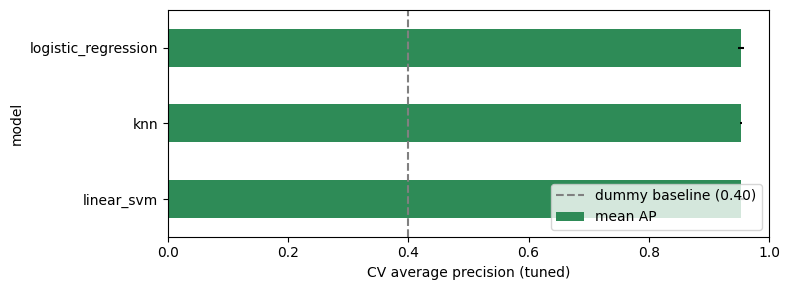

In [10]:
# Tuned CV average precision per model; the error bars are one standard
# error (std / sqrt(folds)), the unit of our decision rule. The dashed line
# is the dummy baseline.
dummy_ap = dummy_scores["test_average_precision"].mean()
standard_error = tuned["std AP"] / np.sqrt(config["cv"]["n_splits"])
ax = tuned["mean AP"].plot.barh(xerr=standard_error, color="seagreen", figsize=(8, 3))
ax.axvline(
    dummy_ap, color="grey", linestyle="--", label=f"dummy baseline ({dummy_ap:.2f})"
)
ax.set_xlim(0, 1)
ax.set_xlabel("CV average precision (tuned)")
ax.invert_yaxis()
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Final model choice

After tuning, the three models are **tied**: logistic regression 0.954, k-NN 0.954 (21 neighbours, weighted by distance) and linear SVM 0.953 average precision, all within one standard error of the best (about 0.005). Tuning mattered most for k-NN: with default settings it was clearly behind (0.921).

The linear SVM's best `C` (100) is the largest value in its grid, so a larger `C` might score a little higher. But its tuned score (0.953) is already within one standard error of logistic regression's, so a small gain would not change our choice, and a larger `C` would make the SVM even slower to train.

Following our decision rule, when scores are tied we keep the simplest model: **logistic regression**. It also gives probabilities directly and its coefficients can be read, which the threshold and the interpretation below rely on.

## Decision threshold

**Why.** For GrandPied, a false positive (a legitimate email blocked) costs more than a false negative (a spam that gets through). So instead of the default threshold of 0.5, we use the lowest threshold that reaches our target precision on spam (`model.target_precision` in `config.yaml`).

**How.** We can't use the test set to choose it, that would leak information. Instead, `cross_val_predict` gives **out-of-fold** probabilities on the training set: each email is scored by a model that did not see it during training. We compute precision and recall for every possible threshold on these probabilities, and keep the lowest threshold whose precision reaches the target.

The hyperparameters were tuned on the same training data, so these out-of-fold scores are slightly optimistic; the test set evaluation below checks the result.

In [11]:
final_trainer = trainers[config["model"]["name"]]   # the tuned final model
target_precision = config["model"]["target_precision"]

oof_spam_probability = cross_val_predict(
    final_trainer.model, X_train, y_train, cv=cv, method="predict_proba"
)[:, SPAM]
precisions, recalls, thresholds = precision_recall_curve(y_train, oof_spam_probability)

# Lowest threshold whose out-of-fold precision reaches the target.
reaches_target = np.where(precisions[:-1] >= target_precision)[0]
chosen_threshold = thresholds[reaches_target[0]] if len(reaches_target) else 1.0
print(f"Chosen threshold: {chosen_threshold:.3f}")

# The CLI uses the threshold saved in config.yaml, so it must be this one.
assert round(chosen_threshold, 3) == config["model"]["threshold"], (
    "update model.threshold in config.yaml"
)

Chosen threshold: 0.782


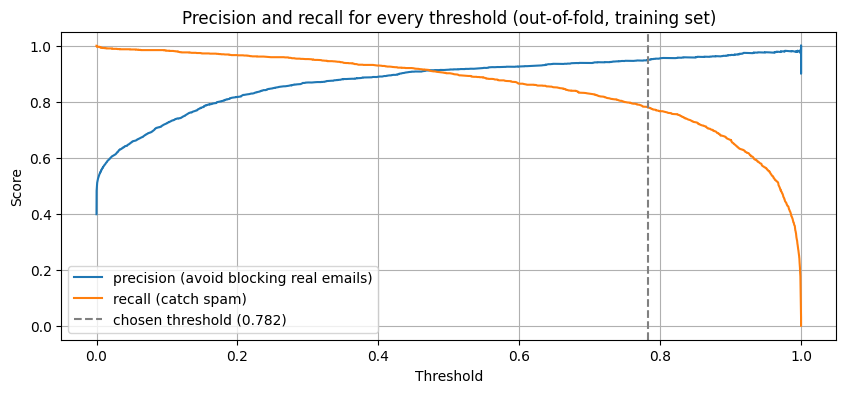

In [12]:
plt.figure(figsize=(10, 4))
plt.plot(thresholds, precisions[:-1], label="precision (avoid blocking real emails)")
plt.plot(thresholds, recalls[:-1], label="recall (catch spam)")
plt.axvline(chosen_threshold, color="grey", linestyle="--",
            label=f"chosen threshold ({chosen_threshold:.3f})")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision and recall for every threshold (out-of-fold, training set)")
plt.legend()
plt.grid(True)
plt.show()

## Test set evaluation

The test set is used **once**, here, with the final model and the threshold from `config.yaml` (the same threshold `spamjam evaluate` uses, so the command line gives the same results).

In [13]:
_, test_df = loader.load_or_create_split()
X_test = test_df.drop(columns=TARGET_COL)
y_test = test_df[TARGET_COL]
test_threshold = config["model"]["threshold"]
test_metrics = final_trainer.evaluate(X_test, y_test, threshold=test_threshold)

pd.Series(
    {name: value for name, value in test_metrics.items() if name != CONFUSION_MATRIX},
    name=f"test set (threshold {test_threshold})",
).round(4)

precision            0.9502
recall               0.7946
f1                   0.8655
roc_auc              0.9765
average_precision    0.9585
Name: test set (threshold 0.782), dtype: float64

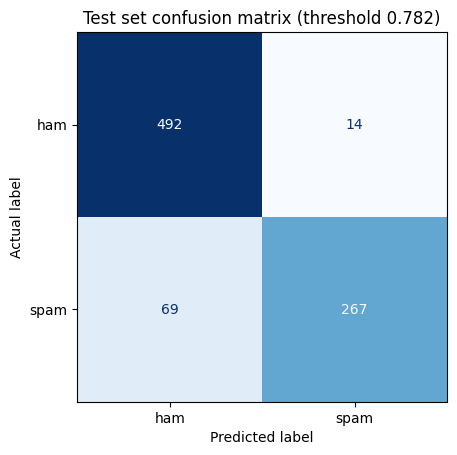

In [14]:
ConfusionMatrixDisplay(
    test_metrics[CONFUSION_MATRIX], display_labels=["ham", "spam"]
).plot(cmap="Blues", colorbar=False)
plt.title(f"Test set confusion matrix (threshold {test_threshold})")
plt.ylabel("Actual label")
plt.xlabel("Predicted label")
plt.show()

**Results on the test set** (842 emails, threshold 0.782):

- **Precision 0.950**: when the model flags an email as spam, it is right 95% of the time, which is the precision we targeted on the training set.
- **Recall 0.795**: it catches about 4 spam out of 5; 69 spam get through.
- **14 of the 506 legitimate emails are flagged as spam.** Each one is a client email someone has to fetch from quarantine, so this is the number GrandPied should watch.
- **ROC-AUC 0.977 and average precision 0.959**: the model ranks spam above ham very well, whatever the threshold.

The test precision matches the 0.95 we targeted on out-of-fold predictions, which is consistent with the threshold choice. The test set is small, though, so this number has a margin of error (see the limitations below). These scores are likely **optimistic for GrandPied**, though: all legitimate emails in Spambase come from one person (see the donor words section and the limitations below), so the model must be retrained on GrandPied's own emails before real use.

## Interpretation

What the final model relies on, its limitations, and what it means for GrandPied.

### Most influential features

The 15 largest coefficients of the final model. Features are scaled, so their sizes can be compared: a positive weight pushes an email towards spam, a negative one towards ham. The feature names come from the pipeline itself, because the preprocessing puts the capital-letter features first, so the columns are not in the same order as in `X_train`.

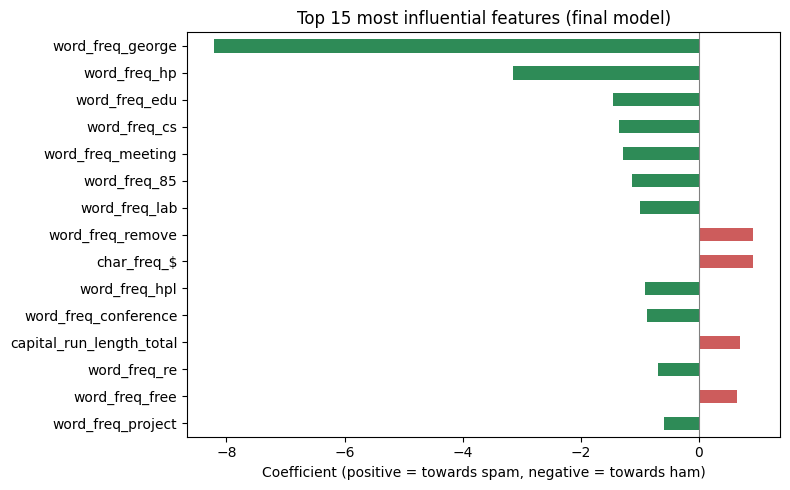

In [15]:
feature_names = [
    name.split("__", 1)[1]   # drop the "capital__" / "other__" prefix
    for name in final_trainer.model["preprocess"].get_feature_names_out()
]
final_coefs = pd.Series(
    final_trainer.model["model"].coef_[0], index=feature_names, name="coefficient"
)
top_features = final_coefs[final_coefs.abs().sort_values(ascending=False).index[:15]]

colors = ["indianred" if weight > 0 else "seagreen" for weight in top_features]
ax = top_features.plot.barh(color=colors, figsize=(8, 5))
ax.axvline(0, color="grey", linewidth=0.8)
ax.invert_yaxis()
ax.set_xlabel("Coefficient (positive = towards spam, negative = towards ham)")
ax.set_title("Top 15 most influential features (final model)")
plt.tight_layout()
plt.show()

**Reading the chart.** The strongest signal by far is `george` (about −8.2, towards ham), followed by other words from the donor's work: `hp`, `edu`, `cs`, `meeting`, `85`, `lab`. The ham side also includes `hpl`, `conference`, `re` and `project`. Towards spam, the strongest are `remove` (as in "remove me from this list"), the `$` sign (`char_freq_$`), the total number of capital letters (`capital_run_length_total`) and `free`. L1 sets `857` and `415` to zero, the two near-duplicate features.

The spam signals make sense for spam in general. The ham signals mostly describe one person, which is the main limitation below.

### Limitations

The full list, with the numbers and examples behind each point, is in [`docs/limitations.md`](../docs/limitations.md). The main ones:

1. **One donor.** All legitimate emails come from one person (George, at HP Labs), and words that describe him, like `george`, `hp` or `edu`, are among the strongest signals towards ham. They won't exist at GrandPied, so our scores are likely optimistic (see the donor words section).
2. **English only.** The 48 word features are English words, so a French email matches none of them and French spam almost always gets through.
3. **GrandPied's emails look like spam to it.** Words a marketing company uses every day push towards spam (`free`, `our`, `business`, `your`), so an ordinary email about a client order can be flagged.
4. **Margin of error.** The test set is small, so the test scores come with an uncertainty (computed below).
5. **Precision depends on the share of spam.** The 0.95 holds for Spambase's mix, about 40 % spam. With less spam it drops (computed below).
6. **Old data.** The dataset was collected around 1999, and spam has changed a lot since then (phishing, image-only spam, obfuscated words).

In [ ]:
def wilson_interval(successes: int, total: int, z: float = 1.96) -> tuple:
    """Return the 95 % Wilson interval for a proportion (reliable for small counts)."""
    share = successes / total
    centre = (share + z**2 / (2 * total)) / (1 + z**2 / total)
    half_width = z * np.sqrt(
        share * (1 - share) / total + z**2 / (4 * total**2)
    ) / (1 + z**2 / total)
    return centre - half_width, centre + half_width


tn, fp, fn, tp = np.ravel(test_metrics[CONFUSION_MATRIX])
counts = {
    "precision": (tp, tp + fp),             # spam among the flagged emails
    "real emails flagged": (fp, fp + tn),   # flagged among the real emails
}
pd.DataFrame(
    [[k / n, *wilson_interval(k, n)] for k, n in counts.values()],
    index=list(counts),
    columns=["test set", "95 % low", "95 % high"],
).round(3)

In [ ]:
# The model's rates (spam caught, real emails flagged) don't depend on how much
# spam there is, but precision does. We recompute it for other shares of spam.
recall = tp / (tp + fn)
false_positive_rate = fp / (fp + tn)
spam_share = pd.Series([0.40, 0.20, 0.10, 0.05])
precision_at_share = spam_share * recall / (
    spam_share * recall + (1 - spam_share) * false_positive_rate
)
pd.DataFrame({"share of spam": spam_share, "precision": precision_at_share}).round(3)

**Reading the numbers.** On another test set of the same size, the precision could be anywhere between about 0.92 and 0.97, so our 0.950 is consistent with the 0.95 target but doesn't prove it. And the 0.95 only holds for Spambase's share of spam (about 40 %): with 10 % spam, the same model would have a precision of about 0.76. GrandPied would have to choose the threshold again on its own emails.

### Risks of deploying it

- **Errors.** Real emails get flagged (14 of 506 on the test set, and more at GrandPied), and each one may be a lost client inquiry.
- **Bias.** The model judges emails that don't look like the donor's (French, marketing) more harshly.
- **Privacy.** It reads the content of every email, which requires informing employees and complying with GDPR.

Details and examples are in [`docs/limitations.md`](../docs/limitations.md).

### Implications for GrandPied

The model can't be used at GrandPied as it is. GrandPied would first retrain it on its own labelled emails (French and English, marketing included) and choose the threshold again on its own share of spam. Flagged emails should go to a quarantine folder that people check, never be deleted. The IT team should also keep an eye on how many real emails get flagged: if clients say their emails went unanswered, the threshold should be raised so that fewer emails are flagged.

## Summary

- **Final model:** logistic regression with L1 regularisation (`C`=1), after a log transform of the capital-letter counts and standard scaling.
- **Model selection** (cross-validation on the training set): average precision 0.954, against 0.399 for the dummy baseline. Tuned k-NN and linear SVM are tied with it; we keep the simplest.
- **Decision threshold:** 0.782, chosen on out-of-fold predictions to reach a precision of 0.95 on spam.
- **Test set** (used once): precision 0.950, recall 0.795; 14 of 506 legitimate emails flagged as spam.
- **Main limitation:** the legitimate emails all come from one person, so these scores are optimistic for GrandPied. The model must be retrained on GrandPied's own emails before real use.